# ECO331 (2026): Explainable Macroeconomic Inflation Forecasting
**Comparing Econometric Benchmarks, Regularized Linear Models, Gradient Boosted Trees (XGBoost), and Deep Sequence Architectures (MLP, LSTM, Temporal Transformer)**

This notebook walks end-to-end through:
1. **FRED Macroeconomic Data & Stationarity Checks** (`1978–2026`, 12 monthly channels)
2. **Storytelling Exploratory Data Analysis** (Regimes, Phillips Curve shifts, Cost-Push nonlinearity, Correlation Matrix)
3. **Multi-Horizon & Regime Model Comparison** ($h \in \{1, 3, 6, 12\}$ months ahead, Diebold-Mariano HAC tests)
4. **Explainable AI (XAI)**: Standardized Elastic Net $\beta$, Exact XGBoost `TreeSHAP`, Local Historical Episode Waterfalls, and `Temporal Transformer` Lag Attention + CV Leakage Audit.

In [1]:
import os, sys
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import FIGURES_DIR, TABLES_DIR
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)

## 1. Macroeconomic Data Dictionary & Unit Root (ADF) Stationarity
Raw price and output indices (`CPIAUCSL`, `CPILFESL`, `PPIACO`, `INDPRO`, `M2SL`) are non-stationary $I(1)$ series. Transforming them into year-over-year percentage rates, annualized momentum, and spreads yields stationary predictors.

In [2]:
adf_df = pd.read_csv(TABLES_DIR / 'data_dictionary_and_adf.csv')
adf_df[['FRED_ID', 'Variable_Name', 'Economic_Channel', 'Raw_ADF_p', 'Model_Transformation', 'Transformed_ADF_p']]

,FRED_ID,Variable_Name,Economic_Channel,Raw_ADF_p,Model_Transformation,Transformed_ADF_p
0,CPIAUCSL,Headline CPI (All Urban Consumers),Target / Price Inertia,0.9978,YoY % Change & 3m Annualized %,0.0001
1,CPILFESL,Core CPI (Less Food & Energy),Underlying Trend Inflation,0.9962,YoY % Change & Core-Headline Spread,0.0002
2,MICH,Univ. of Michigan 1Y Inflation Expectations,Expectations Channel (NKPC),0.0001,Level (%) & 3m Change,0.0000
3,UNRATE,Civilian Unemployment Rate,Phillips Curve / Labor Slack,0.0630,Level (%) & 12m Change (Sahm-style),0.0000
4,INDPRO,Industrial Production Index,Real Activity / Output Growth,0.7230,YoY % Growth,0.0005
5,PPIACO,Producer Price Index (All Commodities),Upstream Cost-Push Supply Shock,0.9963,YoY % Change,0.0000
6,WTISPLC,Spot Crude Oil Price (WTI),Energy / Commodity Shock,0.2453,YoY % Change,0.0000
7,FEDFUNDS,Effective Federal Funds Rate,Monetary Policy Stance,0.0926,"Level (%), Real Policy Rate, 12m Change",0.0000
8,GS10,10-Year Treasury Constant Maturity Rate,Long-Term Bond Market Yields,0.5473,10Y-2Y Term Spread (%),0.0005
9,GS2,2-Year Treasury Constant Maturity Rate,Near-Term Policy Path Expectations,0.3624,10Y-2Y Term Spread (%),0.0005


## 2. Exploratory Data Storytelling (Regimes, Nonlinearity & Correlations)
Notice in **Panel B** below how the empirical Phillips Curve slope shifts dramatically across stagflation, the Great Moderation, and the 2020–2022 supply-shock surge—motivating nonlinear ML and regime-aware ensembles.

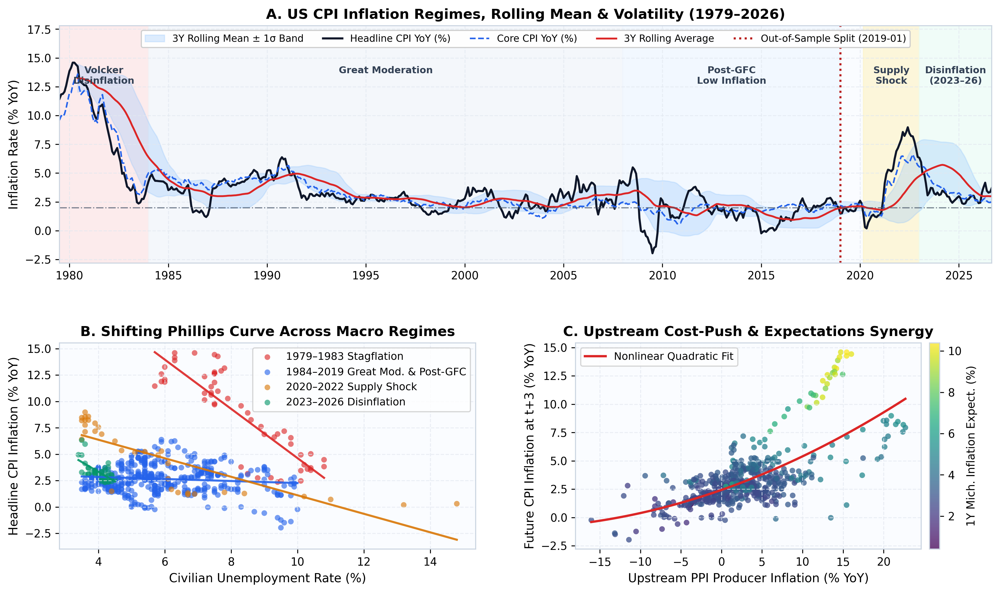

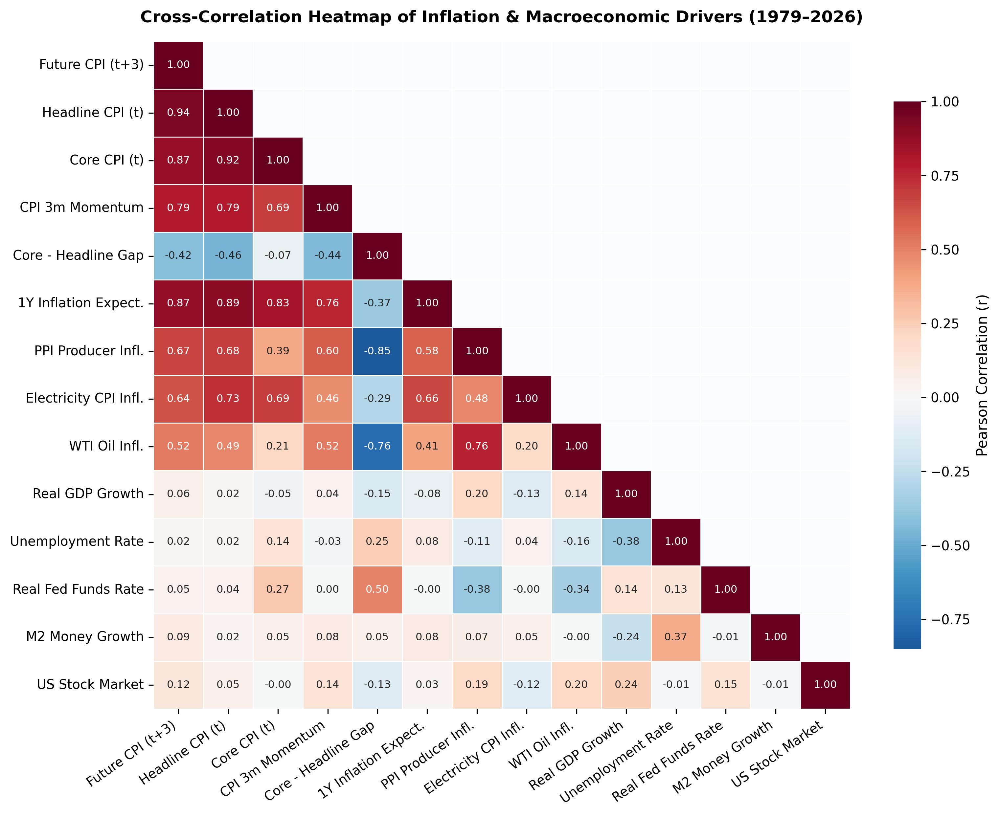

In [3]:
display(Image(filename=str(FIGURES_DIR / 'fig01_eda_storytelling.png'), width=950))
display(Image(filename=str(FIGURES_DIR / 'fig02_correlation_heatmap.png'), width=760))

## 3. Out-of-Sample Model Comparison ($h = 3$ Months Ahead, 2019–2026)
All 11 specifications are trained strictly on pre-2019 observations (with an explicit $h$-month embargo so zero 2019+ targets leak into training) using the anchored decomposition:
$$\hat{\pi}_{t+h} = \pi_t + f_\theta(X_t)$$

In [4]:
h3_df = pd.read_csv(TABLES_DIR / 'metrics_h3_flagship.csv')
h3_df.style.format({
    'RMSE': '{:.3f}', 'MAE': '{:.3f}', 'Rel_RMSE_vs_RW': '{:.3f}',
    'R2': '{:.3f}', 'Directional_Acc_pct': '{:.1f}%',
    'DM_Stat_vs_RW': '{:.2f}', 'DM_p_value': '{:.4f}'
})

,Horizon_Months,Model,Family,RMSE,MAE,Rel_RMSE_vs_RW,R2,Directional_Acc_pct,DM_Stat_vs_RW,DM_p_value
0,3,Elastic Net (L1+L2),2. Regularized Linear,0.777,0.561,0.773,0.873,65.6%,-1.90,0.0604
1,3,XGBoost,3. Tree Ensemble,0.783,0.577,0.779,0.871,66.7%,-2.03,0.0458
2,3,Forecast Combination,6. Cross-Family Ensemble,0.793,0.592,0.790,0.867,64.4%,-1.90,0.0602
3,3,XGB + Deep Net,5. Hybrid Tree + Deep Net,0.829,0.622,0.826,0.855,63.3%,-2.06,0.0421
4,3,Ridge (L2),2. Regularized Linear,0.833,0.600,0.829,0.854,60.0%,-1.54,0.1275
5,3,Random Forest,3. Tree Ensemble,0.838,0.614,0.834,0.852,64.4%,-1.29,0.2009
6,3,MLP (Deep Net),4. Deep Learning,0.869,0.677,0.866,0.840,60.0%,-1.31,0.1924
7,3,Temporal Transformer,4. Deep Learning,0.888,0.629,0.884,0.833,63.3%,-1.11,0.2680
8,3,LSTM (Sequence),4. Deep Learning,0.936,0.718,0.932,0.815,58.9%,-0.72,0.4759
9,3,AR(p) Benchmark,1. Econometric Benchmark,0.937,0.692,0.933,0.815,57.8%,-1.08,0.2841


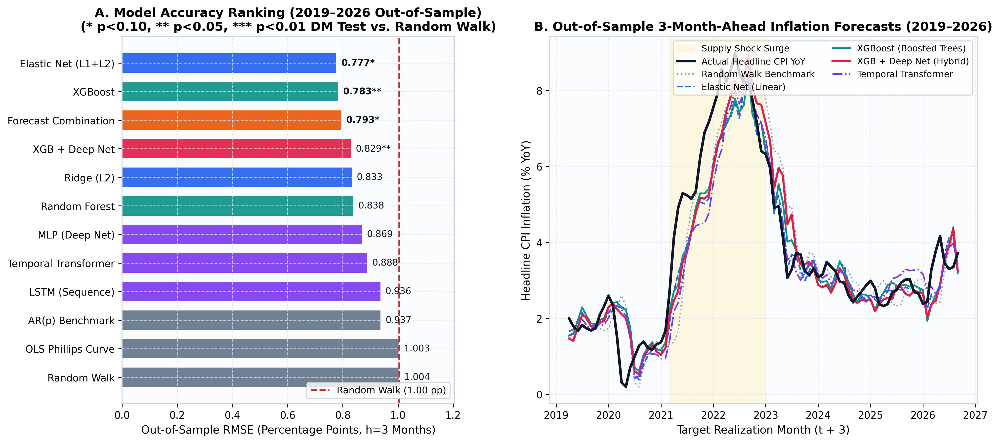

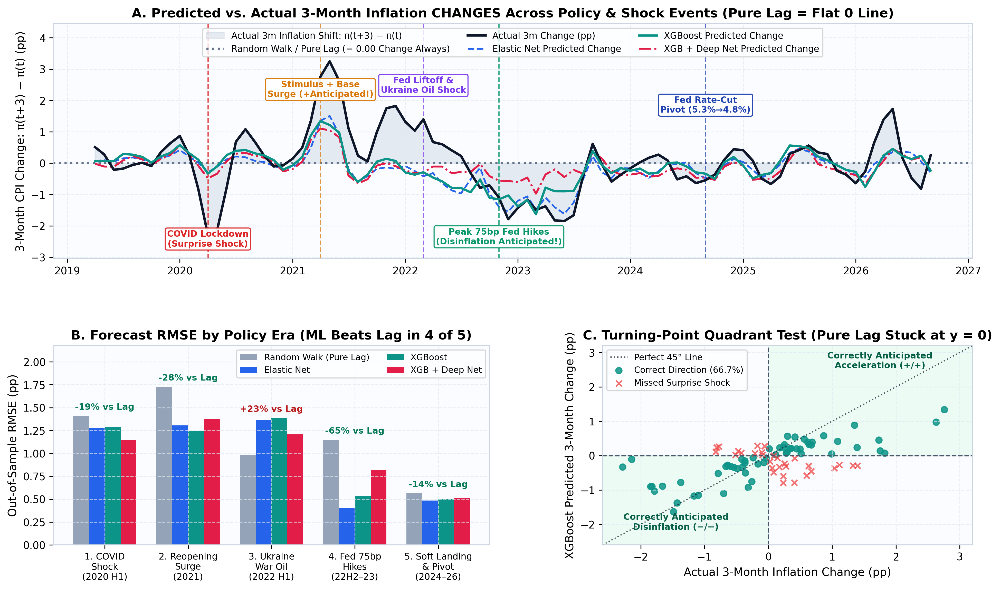

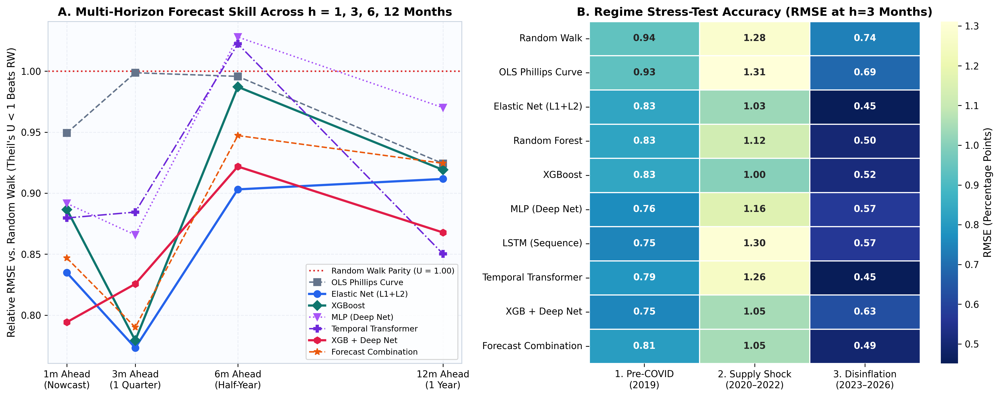

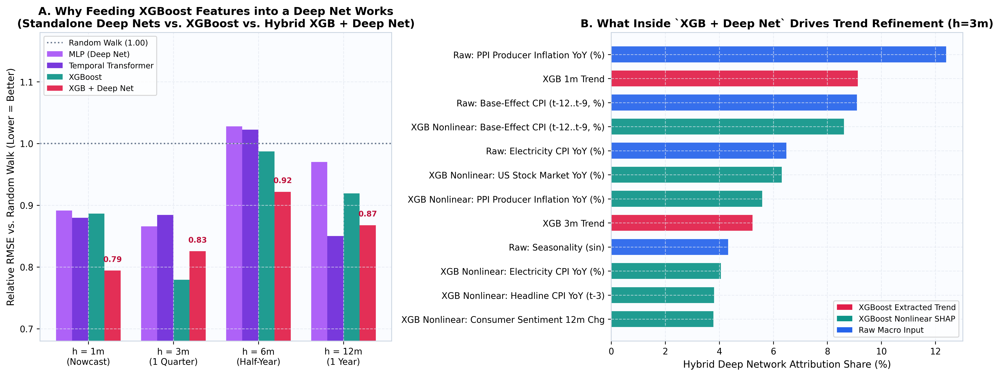

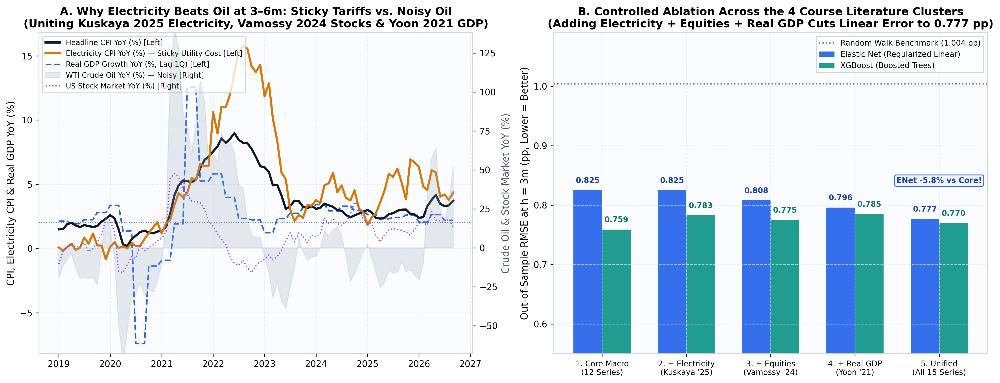

In [5]:
display(Image(filename=str(FIGURES_DIR / 'fig03_model_comparison_h3.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig10_change_and_policy_shocks.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig04_multi_horizon_and_regimes.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig09_hybrid_xgb_deepnet.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig12_cross_paper_synthesis.png'), width=960))

### 3B. Policy Shock Audit & 4-Cluster Course Literature Ablation ($h = 3$m)
Evaluating forecast errors across 5 policy/shock windows AND controlled ablation adding Electricity (`CUSR0000SEHF01`), Equities (`SPASTT01USM661N`), and 1Q-lagged Real GDP (`GDPC1`):

In [6]:
display(pd.read_csv(TABLES_DIR / 'policy_shock_windows_h3.csv').drop(columns=['Plot_Label'], errors='ignore'))
pd.read_csv(TABLES_DIR / 'cross_paper_channel_ablation.csv').drop(columns=['Plot_Label'], errors='ignore')

,Event_Window,Macro_Context,Months,RandomWalk_PureLag_RMSE,ElasticNet_RMSE,XGBoost_RMSE,XGB_DeepNet_RMSE,Best_ML_vs_PureLag_pct
0,1. COVID Lockdown (2020 H1),Exogenous Shock,6,1.409,1.280,1.292,1.144,-18.8
1,2. Reopening Surge (2021),Base Roll-Off + Stimulus,12,1.728,1.307,1.243,1.377,-28.1
2,3. Ukraine Energy Shock (2022 H1),Geopolitical War Surprise,6,0.980,1.361,1.387,1.209,23.4
3,4. Fed 75bp Hikes & Disinflation (22H2–23),Monetary Tightening Turn,18,1.148,0.402,0.535,0.821,-65.0
4,5. Soft Landing & Rate Pivot (2024–26),Policy Normalization,33,0.562,0.486,0.503,0.510,-13.5


,Feature_Set,Course_Literature_Link,Num_FRED_Series,ElasticNet_h3_RMSE,XGBoost_h3_RMSE,Mean_ML_h3_RMSE,ElasticNet_Gain_vs_Core_pct
0,1. Core Macro Baseline (12 FRED Series),CPI & NKPC Core (Singh & Bhoi 2022),12,0.825,0.759,0.792,0.0
1,2. + Electricity Price Index (CUSR0000SEHF01),Sticky Grid Utility Cost (Kuskaya & Bilgili 2025),13,0.825,0.783,0.804,-0.0
2,3. + US Stock Market Index (SPASTT01USM661N),Financial Wealth Effect (Subasi 2021; Vamossy ...,13,0.808,0.775,0.791,-2.0
3,"4. + Real GDP Growth (GDPC1, Lagged 1Q)",Broad Service+Goods Demand (Yoon 2021),13,0.796,0.785,0.791,-3.4
4,5. Unified 4-Cluster Synthesis (All 15 Series),Full Course Literature Integration,15,0.777,0.770,0.773,-5.8


## 4. Multi-Horizon Summary Table ($h \in \{1, 3, 6, 12\}$ Months)

In [7]:
all_h = pd.read_csv(TABLES_DIR / 'metrics_all_horizons.csv')
piv_rmse = all_h.pivot(index='Model', columns='Horizon_Months', values='RMSE')
piv_rmse.columns = [f'RMSE h={c}m' for c in piv_rmse.columns]
piv_rmse.sort_values('RMSE h=3m').round(3)

,RMSE h=1m,RMSE h=3m,RMSE h=6m,RMSE h=12m
Model,,,,
Elastic Net (L1+L2),0.363,0.777,1.447,2.556
XGBoost,0.385,0.783,1.582,2.577
Forecast Combination,0.368,0.793,1.518,2.592
XGB + Deep Net,0.345,0.829,1.477,2.433
Ridge (L2),0.376,0.833,1.530,2.605
Random Forest,0.388,0.838,1.573,2.548
MLP (Deep Net),0.387,0.869,1.648,2.720
Temporal Transformer,0.382,0.888,1.639,2.384
LSTM (Sequence),0.409,0.936,1.649,2.816


## 5. Explainable AI (XAI): Opening the Black Box
We inspect **four complementary explainability lenses**:
1. **Top-Model Driver Consensus** (`Elastic Net` signed $\beta$ vs. `XGBoost` exact `TreeSHAP` vs. `XGB + MLP` Hybrid attribution)
2. **Global Nonlinear SHAP Summary & Threshold Curves**
3. **Local Case-Study Episode Waterfalls** (Inflation Surge vs. Disinflation Turning Point)
4. **Temporal Transformer 2D Sequence Explainability (`h = 12m` #1 Winner) & Random K-Fold Leakage Audit**

In [8]:
imp_df = pd.read_csv(TABLES_DIR / 'explainability_feature_importance.csv')
imp_df[['Feature_Label', 'ElasticNet_Signed_Coef', 'ElasticNet_Share_pct', 'XGBoost_Mean_Abs_SHAP_pp', 'XGBoost_Share_pct', 'XGB_MLP_Share_pct']].head(10).round(3)

,Feature_Label,ElasticNet_Signed_Coef,ElasticNet_Share_pct,XGBoost_Mean_Abs_SHAP_pp,XGBoost_Share_pct,XGB_MLP_Share_pct
0,"Base-Effect CPI (t-12..t-9, %)",-0.702,47.959,0.364,41.931,30.478
1,Electricity CPI YoY (%),-0.000,0.000,0.101,11.620,12.718
2,Headline CPI YoY (t-3),0.000,0.000,0.046,5.295,11.129
3,PPI Producer Inflation YoY (%),0.086,5.862,0.046,5.336,4.495
4,Real Fed Funds Rate (pp),0.000,0.000,0.060,6.952,8.233
5,Core - Headline Gap (pp),0.144,9.859,0.021,2.456,1.105
6,M2 Money Growth YoY (%),0.105,7.171,0.024,2.799,3.337
7,Headline CPI YoY (t-6),0.113,7.736,0.015,1.712,0.969
8,US Stock Market YoY (%),0.049,3.328,0.017,2.000,4.850
9,Industrial Prod. YoY (%),0.002,0.168,0.038,4.421,4.037


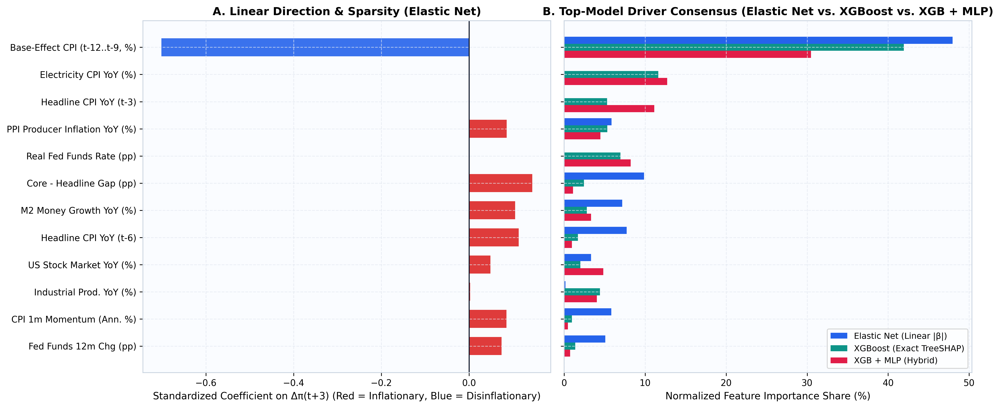

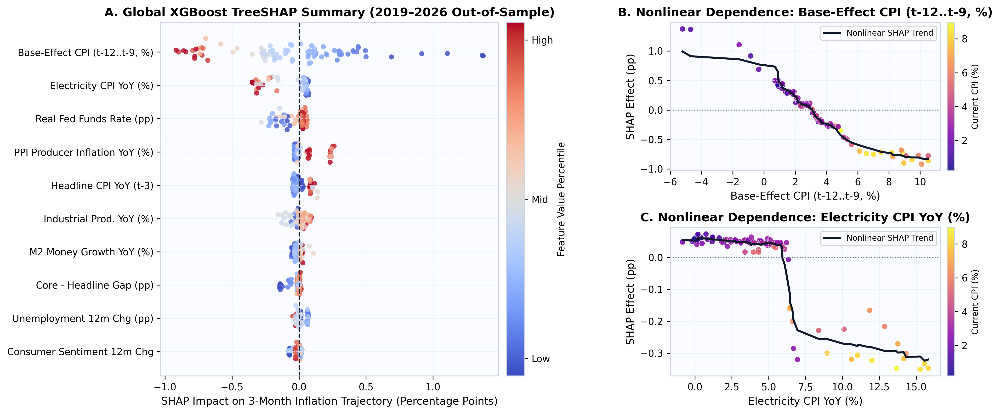

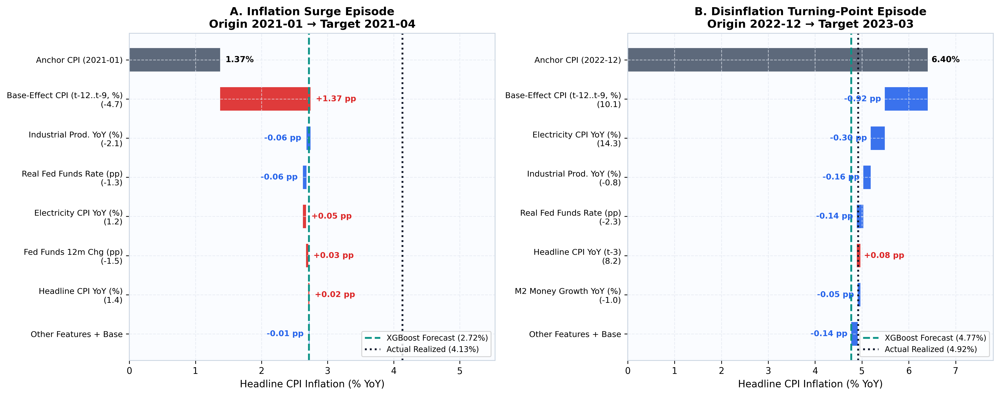

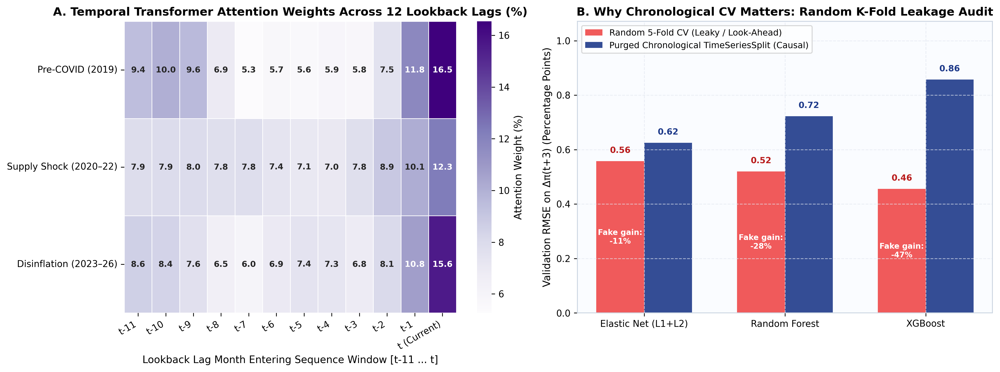

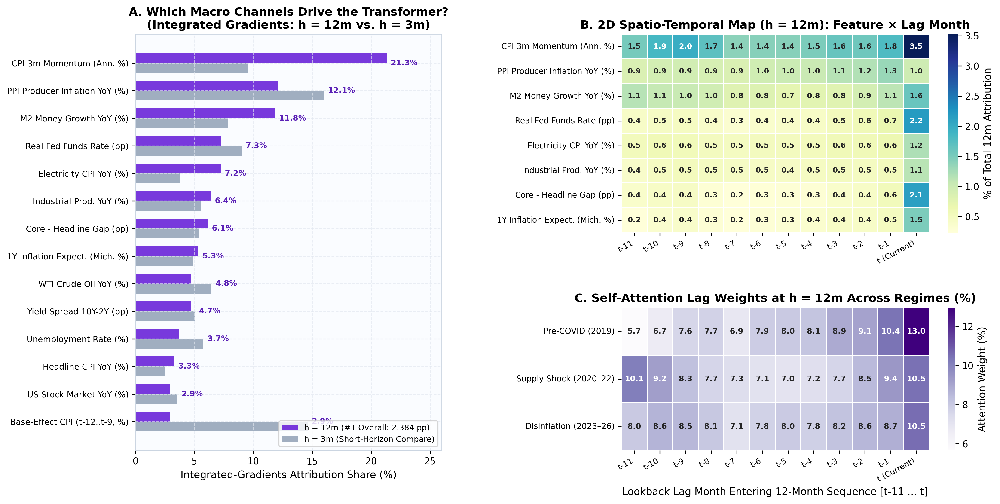

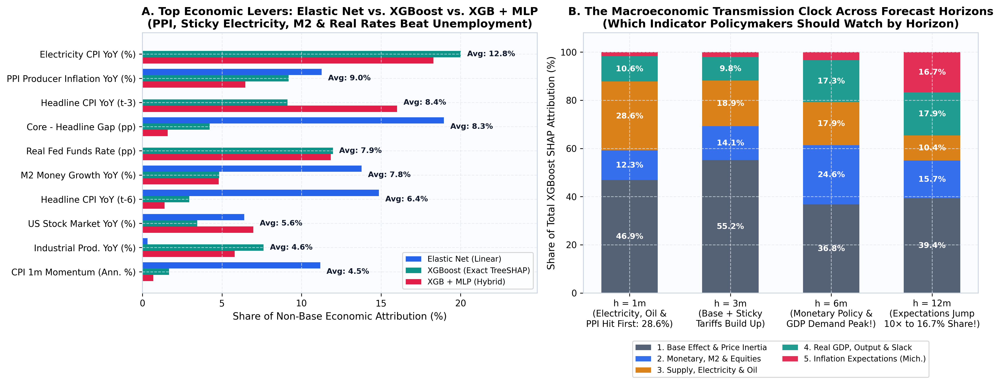

In [9]:
display(Image(filename=str(FIGURES_DIR / 'fig05_xai_cross_family_importance.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig06_shap_global_nonlinear.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig07_shap_episode_waterfalls.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig08_transformer_attention_and_leakage.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig13_transformer_explainability.png'), width=960))
display(Image(filename=str(FIGURES_DIR / 'fig11_xai_policy_playbook.png'), width=960))

### 5B. Actionable Policy Playbook & Macroeconomic Transmission Clock Across Horizons

In [10]:
display(pd.read_csv(TABLES_DIR / 'horizon_channel_shap_shares.csv'))
pd.read_csv(TABLES_DIR / 'xai_policy_playbook.csv')

,Horizon_Months,1. Base Effect & Price Inertia,"2. Monetary, M2 & Equities","3. Supply, Electricity & Oil","4. Real GDP, Output & Slack",5. Inflation Expectations (Mich.)
0,1,46.92,12.30,28.56,10.56,1.66
1,3,55.21,14.05,18.91,9.85,1.98
2,6,36.79,24.61,17.92,17.30,3.39
3,12,39.36,15.66,10.41,17.85,16.72


,Feature,Consensus_Share_pct,XGB_SHAP_Share_pct,ElasticNet_Share_pct,XGB_MLP_Share_pct,Economic_Mechanism,How_Policymakers_and_Analysts_Use_It
0,"Base-Effect CPI (t-12..t-9, %)",40.1,41.9,48.0,30.5,Mechanical Downward Roll-Off (-),Compute t-12..t-9 spike first before judging n...
1,Electricity CPI YoY (%),8.1,11.6,0.0,12.7,Sticky Utility Cost Push (+),Regulated grid electricity tariffs stay sticky...
2,PPI Producer Inflation YoY (%),5.2,5.3,5.9,4.5,Upstream Cost Push (+),Leading 1–3m retail pipeline warning: PPI > +5...
3,Real Fed Funds Rate (pp),5.1,7.0,0.0,8.2,Nonlinear Policy Brake (- above threshold),True monetary stance (Fed Rate - CPI): deeply ...
4,Core - Headline Gap (pp),4.5,2.5,9.9,1.1,Mean-Reversion Anchor (+ toward Core),When Headline > Core (gap < -1.5 pp from oil/f...
5,M2 Money Growth YoY (%),4.4,2.8,7.2,3.3,Liquidity Fuel (+),Medium-term monetary overhang gauge: double-di...
6,US Stock Market YoY (%),3.4,2.0,3.3,4.8,Financial Conditions & Wealth (+),Equity market rallies/drawdowns front-run hous...
7,Industrial Prod. YoY (%),2.9,4.4,0.2,4.0,Real Output / Cyclical Heat (+),Contracting factory output (< 0% YoY) reinforc...
8,CPI 1m Momentum (Ann. %),2.4,1.0,5.8,0.5,High-Frequency Speedometer (+),Annualized 1m pace catches sudden inflection p...
9,WTI Crude Oil YoY (%),2.3,2.0,4.0,1.0,Immediate Energy Shock (+),Strongest at 1m nowcast horizon; watch second-...


## 6. Methodological Check: Why Random K-Fold Leaks Future Inflation

In [11]:
pd.read_csv(TABLES_DIR / 'cv_leakage_diagnostic.csv')

,Model,Random_KFold_RMSE_Leaky,Chronological_Purged_TSCV_RMSE,Artificial_Optimism_Bias_pct
0,Elastic Net (L1+L2),0.558,0.625,10.7
1,Random Forest,0.520,0.723,28.1
2,XGBoost,0.456,0.857,46.8
